# Demo: orquestador multi-agente (pre-entrega 6)

Un **supervisor** recibe el pedido y decide quién trabaja: el **investigador** (base de cobros y
documentación de Tambor) o el **analista** (cálculos y validación). Después de cada aporte lo evalúa
con una rúbrica y, cuando está todo, pasa a la **síntesis**, que redacta la respuesta final.

Este notebook corre el flujo completo contra `claude-haiku-4-5` (la key sale del `.env`) y muestra
cada delegación. Para ejecutarlo de nuevo: abrirlo con el entorno del repo activado y correr todas
las celdas.

In [1]:
import logging, os, sys
from pathlib import Path

# El notebook vive en la raíz del repo: los paquetes se importan desde ahí.
RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ))

logging.basicConfig(level=logging.INFO, format="%(name)s | %(message)s", stream=sys.stdout, force=True)
for ruidoso in ("httpx", "httpx2", "httpcore", "anthropic", "huggingface_hub", "urllib3",
                "pinecone", "rag_pinecone", "rag.embeddings"):
    logging.getLogger(ruidoso).setLevel(logging.WARNING)

from orquestador import construir_orquestador, ejecutar
grafo = construir_orquestador()

## 1. El grafo

Las flechas punteadas son la arista condicional del supervisor (`rutear`, que devuelve un `Literal`).

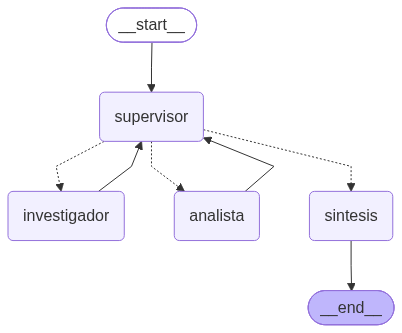

In [2]:
from IPython.display import Image, Markdown, display

try:
    png = grafo.get_graph().draw_mermaid_png()  # usa el servicio mermaid.ink
    (RAIZ / "evidencia" / "grafo_orquestador.png").write_bytes(png)
    display(Image(png))
except Exception as exc:  # sin red: se muestra el texto Mermaid
    print(f"No se pudo renderizar el PNG ({exc}); diagrama en texto:")
    print(grafo.get_graph().draw_mermaid())

## 2. Un pedido que necesita a los dos especialistas

Los logs muestran, en orden, cada evaluación del supervisor y cada aporte.

In [3]:
pedido = ("Analizá los últimos 5 cobros de Ferretería López: qué porcentaje se rechazó, cuánta plata "
          "quedó sin cobrar y qué tiene que hacer el comercio con cada código de error.")
ejecucion = await ejecutar(grafo, pedido)

orquestador.graph | [usuario] Analizá los últimos 5 cobros de Ferretería López: qué porcentaje se rechazó, cuánta plata quedó sin cobrar y qué tiene que hacer el comercio con cada código de error.


orquestador.agents.supervisor | [supervisor] evalúa: No hay aportes aún. El pedido requiere: (1) obtener los últimos 5 cobros de Ferretería López con sus montos y estados, (2) identificar los rechazados y el monto sin cobrar, (3) conocer los códigos de error asociados y sus significados. Todo eso es datos, no cálculos. | -> investigador: Consultá la base de comercios y cobros: traé los últimos 5 cobros de Ferretería López (incluir ID de cobro, monto, estado del cobro, código de error si lo hay). Consultá también la documentación interna: para cada código de error que encuentres, indicá qué significa y qué acción debe tomar el comercio según los procedimientos de Tambor. (El investigador debe traer los últimos 5 cobros de Ferretería López (IDs, montos, estados) y los códigos de error con sus definiciones antes de poder hacer análisis.)


orquestador.agents.especialista | [investigador] recibe: Consultá la base de comercios y cobros: traé los últimos 5 cobros de Ferretería López (incluir ID de cobro, monto, estado del cobro, código de error si lo hay). Consultá también la documentación interna: para cada código de error que encuentres, indicá qué significa y qué acción debe tomar el comercio según los procedimientos de Tambor.


orquestador.agents.especialista | [investigador] aporta en 23.9 s (herramientas: buscar_comercio, listar_cobros, buscar_documentacion, buscar_documentacion): --- ## RESUMEN DE RESULTADOS ### **Últimos 5 cobros de Ferretería López (ID: 102)** | ID Cobro | Fecha | Monto | Estado | Código Error | |----------|-------|-------|--------|--------------| | cob_7F3K2 | 2026-10-06 19:42 | 45.990,00 ARS | ❌ Rechazado | TMB-2031 | | cob_7F1A9 | 2026-10-05 21:03 | 12.


orquestador.agents.supervisor | [supervisor] evalúa: El investigador respondió correctamente: trajo los 5 cobros de Ferretería López con IDs, montos, estados y códigos de error concretos. También consultó la documentación y explicó qué significa cada código de error (TMB-2031 y TMB-2012) y qué debe hacer el comercio. Los datos son verificables y específicos. | -> analista: Con los 5 cobros de Ferretería López que trajo el investigador, calculá: 1) ¿Qué porcentaje fue rechazado? (considera rechazado = estado "Rechazado"). 2) ¿Cuánta plata quedó sin cobrar? (suma los montos de cobros rechazados + en revisión). Reportá los números concretos y las operaciones que hiciste. (Ahora tengo los datos necesarios. El analista debe calcular: porcentaje de cobros rechazados, monto total sin cobrar (rechazados + en revisión), y validar la información contra lo que el investigador trajo.)


orquestador.agents.especialista | [analista] recibe: Con los 5 cobros de Ferretería López que trajo el investigador, calculá: 1) ¿Qué porcentaje fue rechazado? (considera rechazado = estado "Rechazado"). 2) ¿Cuánta plata quedó sin cobrar? (suma los montos de cobros rechazados + en revisión). Reportá los números concretos y las operaciones que hiciste.


orquestador.agents.especialista | [analista] aporta en 8.7 s (herramientas: estadisticas_cobros, calcular): --- ## **RESULTADOS CONCRETOS** ### **1) Porcentaje de cobros rechazados:** **Operación:** 1 cobro rechazado ÷ 5 cobros totales × 100 = **20%** **Desglose:** - Total de cobros: 5 - Cobros rechazados (estado "Rechazado"): 1 → cob_7F3K2 por TMB-2031 (3-D Secure fallida) - Tasa de rechazo: **20,0%** ✓ 


orquestador.agents.supervisor | [supervisor] evalúa: Ambos aportes responden la instrucción. El investigador trajo los 5 cobros concretos (IDs, montos, estados, códigos) y la documentación de cada error. El analista hizo los cálculos solicitados: 20% de rechazo y 58.490,00 ARS sin cobrar (rechazados + en revisión), mostrando las operaciones. Los datos son verificables (IDs específicos, montos exactos, definiciones claras de qué suma cada categoría). El investigador también incluyó qué debe hacer Ferretería López con cada código de error (reintentar para TMB-2031, no crear nuevo cobro para TMB-2012). | -> sintesis: - (Se cubrieron todas las partes del pedido: porcentaje rechazado, plata sin cobrar, y acciones por código de error. Los datos son concretos y están validados. Está todo para redactar la respuesta final.)


orquestador.agents.supervisor | [sintesis] responde: # RESPUESTA - EQUIPO DE ATENCIÓN A COMERCIOS TAMBOR ## Análisis: Últimos 5 cobros de Ferretería López --- ### **Rechazo de cobros** **20% rechazado** (1 de 5 cobros) - ID rechazado: **cob_7F3K2** por código **TMB-2031** --- ### **Dinero sin cobrar** **58.490,00 ARS** en total: - Rechazado: 45.990,00


orquestador.graph | [orquestador] terminado en 48.9 s: supervisor -> investigador -> supervisor -> analista -> supervisor -> sintesis


## 3. Las delegaciones del supervisor

In [4]:
print("Recorrido:", " -> ".join(ejecucion.recorrido), f"({ejecucion.duracion_ms / 1000:.1f} s)\n")
for i, d in enumerate(ejecucion.decisiones, start=1):
    print(f"{i}. -> {d.siguiente}")
    print(f"   evaluación: {d.evaluacion}")
    print(f"   instrucción: {d.instruccion or '-'}\n")

Recorrido: supervisor -> investigador -> supervisor -> analista -> supervisor -> sintesis (48.9 s)

1. -> investigador
   evaluación: No hay aportes aún. El pedido requiere: (1) obtener los últimos 5 cobros de Ferretería López con sus montos y estados, (2) identificar los rechazados y el monto sin cobrar, (3) conocer los códigos de error asociados y sus significados. Todo eso es datos, no cálculos.
   instrucción: Consultá la base de comercios y cobros: traé los últimos 5 cobros de Ferretería López (incluir ID de cobro, monto, estado del cobro, código de error si lo hay). Consultá también la documentación interna: para cada código de error que encuentres, indicá qué significa y qué acción debe tomar el comercio según los procedimientos de Tambor.

2. -> analista
   evaluación: El investigador respondió correctamente: trajo los 5 cobros de Ferretería López con IDs, montos, estados y códigos de error concretos. También consultó la documentación y explicó qué significa cada código de erro

## 4. Qué aportó cada especialista

In [5]:
for a in ejecucion.aportes:
    print(f"[{a.agente}] {a.ms / 1000:.1f} s, herramientas: {', '.join(a.herramientas)}")
    print(a.contenido, "\n" + "-" * 80)

[investigador] 23.9 s, herramientas: buscar_comercio, listar_cobros, buscar_documentacion, buscar_documentacion
---

## RESUMEN DE RESULTADOS

### **Últimos 5 cobros de Ferretería López (ID: 102)**

| ID Cobro | Fecha | Monto | Estado | Código Error |
|----------|-------|-------|--------|--------------|
| cob_7F3K2 | 2026-10-06 19:42 | 45.990,00 ARS | ❌ Rechazado | TMB-2031 |
| cob_7F1A9 | 2026-10-05 21:03 | 12.500,00 ARS | ⏳ En revisión | TMB-2012 |
| cob_7E8Q4 | 2026-10-04 11:15 | 8.700,00 ARS | ✅ Aprobado | — |
| cob_7E2M7 | 2026-10-02 16:48 | 23.100,00 ARS | ✅ Aprobado | — |
| cob_7D9X1 | 2026-09-29 10:05 | 159.000,00 ARS | ↩️ Reembolsado | — |

---

### **Documentación de Códigos de Error**

#### **TMB-2031** (Cobro: cob_7F3K2 - Rechazado)
- **Mensaje:** Autenticación 3-D Secure fallida
- **Causa:** El comprador no completó el desafío de 3-D Secure o lo completó mal
- **Acción requerida:** 
  - Ofrecer reintentar el pago
  - **Advertencia:** Después de 3 intentos fallidos, la tarj

## 5. Respuesta final (síntesis)

In [6]:
display(Markdown(ejecucion.respuesta_final))

# RESPUESTA - EQUIPO DE ATENCIÓN A COMERCIOS TAMBOR

## Análisis: Últimos 5 cobros de Ferretería López

---

### **Rechazo de cobros**
**20% rechazado** (1 de 5 cobros)
- ID rechazado: **cob_7F3K2** por código **TMB-2031**

---

### **Dinero sin cobrar**
**58.490,00 ARS** en total:
- Rechazado: 45.990,00 ARS (cob_7F3K2)
- En revisión: 12.500,00 ARS (cob_7F1A9)

---

### **Acciones por código de error**

| Código | ID Cobro | Problema | Qué hacer |
|--------|----------|----------|-----------|
| **TMB-2031** | cob_7F3K2 | Autenticación 3-D Secure fallida | Ofrecer reintentar. ⚠️ Máx 3 intentos o la tarjeta se bloquea 24 horas |
| **TMB-2012** | cob_7F1A9 | Timeout del adquirente (estado incierto) | NO crear cobro nuevo. Consultar con `GET /v2/cobros/cob_7F1A9`. Tambor resuelve en máx 2 horas |

---

**Nota:** 2 cobros aprobados (31.800,00 ARS) y 1 reembolsado (159.000,00 ARS).